<a href="https://colab.research.google.com/github/Chithra679/AI-based-project/blob/main/Copy_of_Tumakuru_LULC_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip -q install earthengine-api geemap pandas numpy matplotlib scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 66.8 MB/s eta 0:00:00


In [ ]:
import ee
import geemap
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

ee.Authenticate()

# Replace this with your own Earth Engine-enabled
# Google Cloud project ID.
ee.Initialize(project="neon-mote-511313-v8")

print("Earth Engine is ready!")

Earth Engine is ready!


*** Earth Engine *** Share your feedback by taking our Annual Developer Satisfaction Survey: https://google.qualtrics.com/jfe/form/SV_9oS0DRcPvElRMNw?source=python


In [ ]:
districts = ee.FeatureCollection(
    "FAO/GAUL/2015/level2"
)

tumkur = districts.filter(
    ee.Filter.And(
        ee.Filter.eq("ADM0_NAME", "India"),
        ee.Filter.eq("ADM1_NAME", "Karnataka"),
        ee.Filter.inList(
            "ADM2_NAME", ["Tumkur", "Tumakuru"]
        )
    )
)

print("Matching districts:", tumkur.size().getInfo())

/usr/local/lib/python3.13/dist-packages/ee/deprecation.py:215: DeprecationWarning: 

Attention required for FAO/GAUL/2015/level2! You are using a deprecated asset.
To make sure your code keeps working, please update it.
This dataset has been superseded by FAO/GAUL/2025/level2

Learn more: https://developers.google.com/earth-engine/datasets/catalog/FAO_GAUL_2015_level2

  warnings.warn(warning, category=DeprecationWarning)


Matching districts: 1


In [ ]:
print("District count:", tumkur.size().getInfo())

print(
    "District name:",
    tumkur.aggregate_array("ADM2_NAME").getInfo()
)

boundary = tumkur.geometry()

print("Boundary loaded successfully!")

District count: 1
District name: ['Tumkur']
Boundary loaded successfully!


In [ ]:
Map = geemap.Map()

Map.centerObject(tumkur, 9)

Map.addLayer(
    tumkur,
    {"color": "yellow"},
    "Tumakuru District"
)

Map

Map(center=[13.513107372233279, 76.94110687019399], controls=(WidgetControl(options=['position', 'transparent_…

In [ ]:
Map = geemap.Map(
    basemap="SATELLITE"
)

Map.centerObject(tumkur, 9)

Map.addLayer(
    tumkur.style(
        color="yellow",
        fillColor="00000000",
        width=3
    ),
    {},
    "Tumakuru District Boundary"
)

Map

Map(center=[13.513107372233279, 76.94110687019399], controls=(WidgetControl(options=['position', 'transparent_…

In [ ]:
# Load Landsat imagery for 2025

image_2025 = get_landsat_composite(
    2025,
    tumkur.geometry()
)

# Display the satellite image
Map = geemap.Map(basemap="SATELLITE")
Map.centerObject(tumkur, 9)

Map.addLayer(
    image_2025,
    {
        "bands": ["red", "green", "blue"],
        "min": 0.0,
        "max": 0.3
    },
    "Landsat 2025"
)

Map.addLayer(
    tumkur.style(
        color="yellow",
        fillColor="00000000",
        width=2
    ),
    {},
    "Tumakuru Boundary"
)

Map

NameError: name 'get_landsat_composite' is not defined

In [ ]:
import ee

def prepare_landsat(image, sensor):
    if sensor in ["L5", "L7"]:
        bands = [
            "SR_B1", "SR_B2", "SR_B3",
            "SR_B4", "SR_B5", "SR_B7"
        ]
    else:
        bands = [
            "SR_B2", "SR_B3", "SR_B4",
            "SR_B5", "SR_B6", "SR_B7"
        ]

    qa = image.select("QA_PIXEL")
    cloud = qa.bitwiseAnd(1 << 3).neq(0)
    shadow = qa.bitwiseAnd(1 << 4).neq(0)
    cirrus = qa.bitwiseAnd(1 << 2).neq(0)

    mask = cloud.Or(shadow).Or(cirrus).Not()

    optical = (
        image.select(bands)
        .multiply(0.0000275)
        .add(-0.2)
        .rename([
            "blue", "green", "red",
            "nir", "swir1", "swir2"
        ])
    )

    return optical.updateMask(mask)


def get_landsat_composite(year, boundary):
    start = ee.Date.fromYMD(year, 1, 1)
    end = ee.Date.fromYMD(year + 1, 1, 1)

    collections = [
        ("LANDSAT/LT05/C02/T1_L2", "L5"),
        ("LANDSAT/LE07/C02/T1_L2", "L7"),
        ("LANDSAT/LC08/C02/T1_L2", "L8"),
        ("LANDSAT/LC09/C02/T1_L2", "L9")
    ]

    merged = ee.ImageCollection([])

    for dataset, sensor in collections:
        collection = (
            ee.ImageCollection(dataset)
            .filterDate(start, end)
            .filterBounds(boundary)
            .map(
                lambda img, s=sensor:
                prepare_landsat(img, s)
            )
        )
        merged = merged.merge(collection)

    return merged.median().clip(boundary)


boundary = tumkur.geometry()

image_2025 = get_landsat_composite(
    2025, boundary
)

print("2025 Landsat composite created!")

2025 Landsat composite created!


In [ ]:
Map = geemap.Map(basemap="SATELLITE")
Map.centerObject(tumkur, 9)

Map.addLayer(
    image_2025,
    {
        "bands": ["red", "green", "blue"],
        "min": 0,
        "max": 0.3
    },
    "Landsat 2025"
)

Map.addLayer(
    tumkur.style(
        color="yellow",
        fillColor="00000000",
        width=2
    ),
    {},
    "Tumakuru Boundary"
)

Map

Map(center=[13.513107372233279, 76.94110687019399], controls=(WidgetControl(options=['position', 'transparent_…

In [ ]:
# Check that the 2025 Landsat image has valid pixels
print(
    "Valid pixels:",
    image_2025.select("red").reduceRegion(
        reducer=ee.Reducer.count(),
        geometry=tumkur.geometry(),
        scale=300,
        maxPixels=1e8,
        bestEffort=True
    ).getInfo()
)

Valid pixels: {'red': 121754}


In [ ]:
# Add spectral indices to the 2025 image

ndvi = image_2025.normalizedDifference(
    ["nir", "red"]
).rename("NDVI")

ndwi = image_2025.normalizedDifference(
    ["green", "nir"]
).rename("NDWI")

ndbi = image_2025.normalizedDifference(
    ["swir1", "nir"]
).rename("NDBI")

features_2025 = image_2025.addBands(
    [ndvi, ndwi, ndbi]
)

print("Spectral indices created successfully!")

Spectral indices created successfully!


In [ ]:
# Load ESA WorldCover reference data
worldcover = (
    ee.ImageCollection("ESA/WorldCover/v200")
    .first()
    .select("Map")
)

# Convert original WorldCover classes into our
# five project classes:
# 0 = Built-up
# 1 = Agriculture
# 2 = Vegetation
# 3 = Barren land
# 4 = Water

original_classes = [
    10, 20, 30, 40, 50, 60, 80, 90, 95, 100
]

project_classes = [
    2, 2, 2, 1, 0, 3, 4, 2, 2, 2
]

labels = (
    worldcover.remap(
        original_classes,
        project_classes
    )
    .rename("class")
    .clip(tumkur.geometry())
)

# Keep pixels with one of the five known classes
valid_labels = labels.gte(0).And(labels.lte(4))

print("Reference land-cover labels prepared!")

Reference land-cover labels prepared!


In [ ]:
predictor_bands = [
    "blue", "green", "red", "nir",
    "swir1", "swir2", "NDVI", "NDWI", "NDBI"
]

# Combine Landsat features with reference labels
training_image = (
    features_2025.select(predictor_bands)
    .addBands(labels)
    .updateMask(valid_labels)
)

samples = training_image.stratifiedSample(
    numPoints=500,
    classBand="class",
    region=tumkur.geometry(),
    scale=30,
    seed=42,
    geometries=True,
    tileScale=4
)

print("Total samples:", samples.size().getInfo())

print(
    "Samples per class:",
    samples.aggregate_histogram("class").getInfo()
)

Total samples: 2500
Samples per class: {'0': 500, '1': 500, '2': 500, '3': 500, '4': 500}


In [ ]:
# Split samples into training and testing subsets
samples = samples.randomColumn("random", seed=42)

train = samples.filter(
    ee.Filter.lt("random", 0.7)
)

test = samples.filter(
    ee.Filter.gte("random", 0.7)
)

classifier = ee.Classifier.smileRandomForest(
    numberOfTrees=200,
    seed=42
).train(
    features=train,
    classProperty="class",
    inputProperties=predictor_bands
)

lulc_2025 = (
    features_2025.select(predictor_bands)
    .classify(classifier)
    .rename("LULC")
)

print("Random Forest classification completed!")

Random Forest classification completed!


In [ ]:
Map = geemap.Map(basemap="SATELLITE")
Map.centerObject(tumkur, 9)

Map.addLayer(
    lulc_2025,
    {
        "min": 0,
        "max": 4,
        "palette": [
            "red",       # 0 Built-up
            "yellow",    # 1 Agriculture
            "green",     # 2 Vegetation
            "brown",     # 3 Barren land
            "blue"       # 4 Water
        ]
    },
    "Tumakuru LULC 2025"
)

Map.addLayer(
    tumkur.style(
        color="white",
        fillColor="00000000",
        width=2
    ),
    {},
    "District Boundary"
)

Map

Map(center=[13.513107372233279, 76.94110687019399], controls=(WidgetControl(options=['position', 'transparent_…

In [ ]:
# Evaluate the Random Forest classifier
validated = test.classify(classifier)

error_matrix = validated.errorMatrix(
    "class",
    "classification"
)

print("Confusion Matrix:")
print(error_matrix.getInfo())

print(
    "Overall Accuracy:",
    error_matrix.accuracy().getInfo()
)

print(
    "Kappa Coefficient:",
    error_matrix.kappa().getInfo()
)

Confusion Matrix:
[[93, 15, 8, 22, 0], [13, 107, 19, 7, 2], [10, 30, 93, 3, 3], [19, 7, 2, 98, 12], [1, 0, 0, 8, 140]]
Overall Accuracy: 0.7457865168539326
Kappa Coefficient: 0.6819930462505769


In [ ]:
# Calculate area of each LULC class in square kilometres

area_image = (
    ee.Image.pixelArea()
    .divide(1e6)
    .rename("area_km2")
    .addBands(lulc_2025.rename("class"))
)

area_result = area_image.reduceRegion(
    reducer=ee.Reducer.sum().group(
        groupField=1,
        groupName="class"
    ),
    geometry=tumkur.geometry(),
    scale=30,
    maxPixels=1e13,
    tileScale=4
)

groups = area_result.get("groups").getInfo()

class_names = {
    0: "Built-up",
    1: "Agriculture",
    2: "Vegetation",
    3: "Barren land",
    4: "Water bodies"
}

rows = []

for item in groups:
    class_id = int(item["class"])
    rows.append({
        "Class": class_names.get(class_id, "Unknown"),
        "Area (sq. km)": round(item["sum"], 2)
    })

area_df = pd.DataFrame(rows)

print("Tumakuru LULC Area Statistics — 2025")
display(area_df)
print("Total classified area:", round(
    area_df["Area (sq. km)"].sum(), 2
), "sq. km")

Tumakuru LULC Area Statistics — 2025


,Class,Area (sq. km)
0,Built-up,936.51
1,Agriculture,4789.20
2,Vegetation,4136.92
3,Barren land,471.58
4,Water bodies,257.69


Total classified area: 10591.9 sq. km


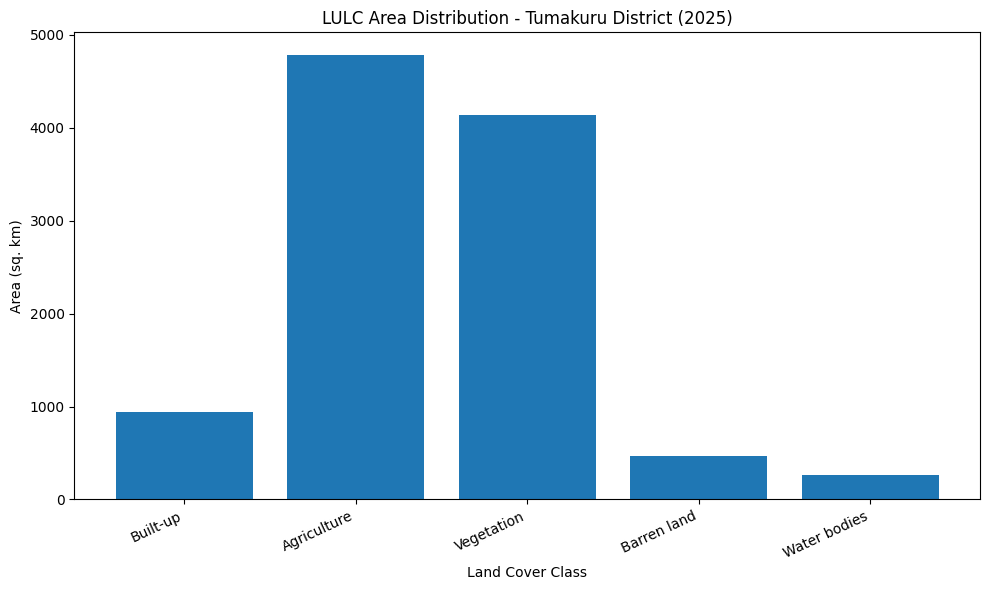

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.bar(
    area_df["Class"],
    area_df["Area (sq. km)"]
)

plt.title("LULC Area Distribution - Tumakuru District (2025)")
plt.xlabel("Land Cover Class")
plt.ylabel("Area (sq. km)")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

In [ ]:
# Historical Landsat composites for Tumakuru
# Requires your existing `ee` and `tumkur` variables.

def get_landsat_composite(year, region):
    start = f"{year}-01-01"
    end = f"{year + 1}-01-01"

    if year <= 2011:
        collection = (
            ee.ImageCollection("LANDSAT/LT05/C02/T1_L2")
            .filterBounds(region)
            .filterDate(start, end)
        )

        def prepare(image):
            optical = (
                image.select(
                    ["SR_B1", "SR_B2", "SR_B3",
                     "SR_B4", "SR_B5", "SR_B7"],
                    ["blue", "green", "red",
                     "nir", "swir1", "swir2"]
                )
                .multiply(0.0000275)
                .add(-0.2)
            )

            qa = image.select("QA_PIXEL")
            mask = (
                qa.bitwiseAnd(1 << 1).eq(0)
                .And(qa.bitwiseAnd(1 << 3).eq(0))
                .And(qa.bitwiseAnd(1 << 4).eq(0))
                .And(qa.bitwiseAnd(1 << 5).eq(0))
            )
            return optical.updateMask(mask)

    else:
        collection = (
            ee.ImageCollection("LANDSAT/LC08/C02/T1_L2")
            .filterBounds(region)
            .filterDate(start, end)
        )

        def prepare(image):
            optical = (
                image.select(
                    ["SR_B2", "SR_B3", "SR_B4",
                     "SR_B5", "SR_B6", "SR_B7"],
                    ["blue", "green", "red",
                     "nir", "swir1", "swir2"]
                )
                .multiply(0.0000275)
                .add(-0.2)
            )

            qa = image.select("QA_PIXEL")
            mask = (
                qa.bitwiseAnd(1 << 1).eq(0)
                .And(qa.bitwiseAnd(1 << 2).eq(0))
                .And(qa.bitwiseAnd(1 << 3).eq(0))
                .And(qa.bitwiseAnd(1 << 4).eq(0))
                .And(qa.bitwiseAnd(1 << 5).eq(0))
            )
            return optical.updateMask(mask)

    collection = collection.map(prepare)

    print(
        year,
        "images available:",
        collection.size().getInfo()
    )

    return collection.median().clip(region)


image_2001 = get_landsat_composite(2001, tumkur.geometry())
image_2025 = get_landsat_composite(2025, tumkur.geometry())

print("Historical composites created successfully.")

2001 images available: 13
2025 images available: 76
Historical composites created successfully.


In [ ]:
import geemap

Map = geemap.Map()

# Display 2001 satellite composite
Map.addLayer(
    image_2001,
    {
        "bands": ["red", "green", "blue"],
        "min": 0.0,
        "max": 0.3
    },
    "Landsat 2001"
)

# Display 2025 satellite composite
Map.addLayer(
    image_2025,
    {
        "bands": ["red", "green", "blue"],
        "min": 0.0,
        "max": 0.3
    },
    "Landsat 2025"
)

Map.centerObject(tumkur, 8)
Map.addLayer(
    tumkur.style(
        color="yellow",
        fillColor="00000000",
        width=2
    ),
    {},
    "Tumakuru Boundary"
)

Map.addLayerControl()
Map

Map(center=[13.513107372233279, 76.94110687019399], controls=(WidgetControl(options=['position', 'transparent_…

In [ ]:
Map = geemap.Map(basemap="SATELLITE")
Map.centerObject(tumkur, 9)
Map.addLayer(tumkur.style(
    color="yellow",
    fillColor="00000000",
    width=2
), {}, "Tumakuru Boundary")
Map

Map(center=[13.513107372233279, 76.94110687019399], controls=(WidgetControl(options=['position', 'transparent_…

In [ ]:
# Compare land use in 2001 and 2025

print("2001 image available:", image_2001 is not None)
print("2025 image available:", image_2025 is not None)

print("2001 and 2025 images are ready for comparison.")

2001 image available: True
2025 image available: True
2001 and 2025 images are ready for comparison.


In [ ]:
# Land Use and Land Cover comparison: 2001 vs 2025

import ee
import pandas as pd

# Class names and IDs from your existing classification
class_names = [
    "Built-up",
    "Agriculture",
    "Vegetation",
    "Barren land",
    "Water bodies"
]

# Check the image bands before proceeding
print("2001 bands:", image_2001.bandNames().getInfo())
print("2025 bands:", image_2025.bandNames().getInfo())

2001 bands: ['blue', 'green', 'red', 'nir', 'swir1', 'swir2']
2025 bands: ['blue', 'green', 'red', 'nir', 'swir1', 'swir2']
